In [8]:
import torch
import torch.nn as nn
import pandas as pd

from datasets import load_dataset
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

'_ssl.c:989: The handshake operation timed out' thrown while requesting HEAD https://huggingface.co/datasets/ucirvine/sms_spam/resolve/cae486f927c250fe1d4a5b55f11357964ed1646c/dataset_infos.json
Retrying in 1s [Retry 1/5].
'_ssl.c:989: The handshake operation timed out' thrown while requesting HEAD https://huggingface.co/datasets/ucirvine/sms_spam/resolve/cae486f927c250fe1d4a5b55f11357964ed1646c/dataset_infos.json
Retrying in 2s [Retry 2/5].


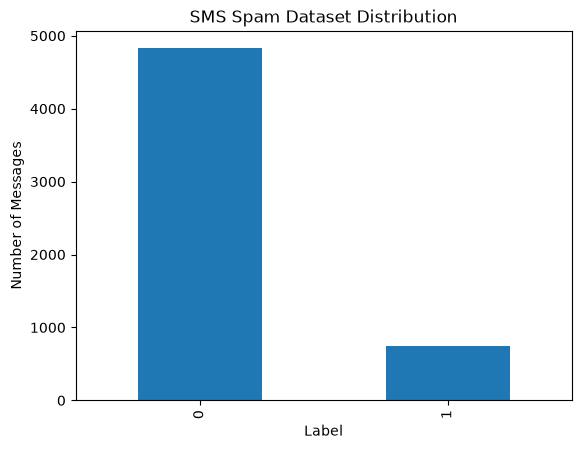

In [10]:
dataset = load_dataset("ucirvine/sms_spam", split="train").to_pandas()

label_counts = dataset["label"].value_counts()
label_counts.plot(kind="bar",title="SMS Spam Dataset Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Messages")
plt.show()

X = dataset["sms"]
y = dataset["label"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


In [11]:
vectorizer = CountVectorizer(stop_words="english",max_features=5000)

X_train = vectorizer.fit_transform(X_train).toarray()
X_test = vectorizer.transform(X_test).toarray()

In [12]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train.values, dtype=torch.long).view(-1, 1)
y_test = torch.tensor(y_test.values, dtype=torch.long).view(-1, 1)

y_train = y_train.squeeze().long()
y_test = y_test.squeeze().long()


In [13]:

model = nn.Sequential(
    nn.Linear(X_train.shape[1], 256),
    nn.ReLU(),

    nn.Linear(256, 128),
    nn.ReLU(),

    nn.Linear(128, 64),
    nn.ReLU(),

    nn.Linear(64, 2)
)

loss = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(50):

    model.train()
    forward = model(X_train)
    loss_value = loss(forward, y_train)
    optimizer.zero_grad()
    loss_value.backward()
    optimizer.step()

    print(f"Epoch: {epoch+1}, Loss: {loss_value.item()}")


Epoch: 1, Loss: 0.6839859485626221
Epoch: 2, Loss: 0.673775851726532
Epoch: 3, Loss: 0.6652341485023499
Epoch: 4, Loss: 0.6572012305259705
Epoch: 5, Loss: 0.6488686800003052
Epoch: 6, Loss: 0.6399380564689636
Epoch: 7, Loss: 0.6302679777145386
Epoch: 8, Loss: 0.6198047995567322
Epoch: 9, Loss: 0.608553946018219
Epoch: 10, Loss: 0.5963846445083618
Epoch: 11, Loss: 0.5829592943191528
Epoch: 12, Loss: 0.5677568316459656
Epoch: 13, Loss: 0.5501241683959961
Epoch: 14, Loss: 0.5297484993934631
Epoch: 15, Loss: 0.5063958764076233
Epoch: 16, Loss: 0.4798952341079712
Epoch: 17, Loss: 0.4502983093261719
Epoch: 18, Loss: 0.4178397059440613
Epoch: 19, Loss: 0.3829053044319153
Epoch: 20, Loss: 0.3460901975631714
Epoch: 21, Loss: 0.3082111179828644
Epoch: 22, Loss: 0.27020537853240967
Epoch: 23, Loss: 0.23306578397750854
Epoch: 24, Loss: 0.1978018879890442
Epoch: 25, Loss: 0.1653032898902893
Epoch: 26, Loss: 0.13624544441699982
Epoch: 27, Loss: 0.11102412641048431
Epoch: 28, Loss: 0.0897273793816566

In [14]:
model.eval()

with torch.no_grad():
    forward = model(X_test)
    predictions = torch.argmax(forward, dim=1)
    accuracy = accuracy_score(y_test.numpy(), predictions.numpy())
    print("Accuracy:", accuracy)



Accuracy: 0.9856502242152466


Accuracy: 0.9856502242152466


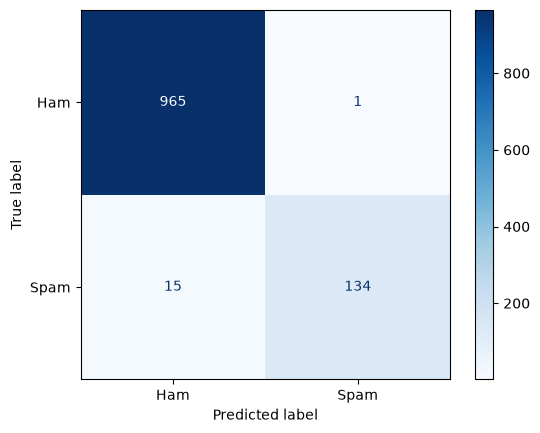

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model.eval()

with torch.no_grad():
    outputs = model(X_test)
    predictions = torch.argmax(outputs, dim=1)
    accuracy = accuracy_score(y_test.numpy(), predictions.numpy())
    print("Accuracy:", accuracy)

cm = confusion_matrix(y_test.numpy(), predictions.numpy())
display = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Ham", "Spam"])
display.plot(cmap="Blues")

plt.show()